In [1]:
import os
# performance test for single-core
os.sched_setaffinity(0, {0})

import time
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline

import jax
jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platform_name", "gpu")

import jax.numpy as jnp
from collections import namedtuple

import taichi as ti
ti.init(
    arch=ti.cpu,
    default_fp=ti.f64,
    cpu_max_num_threads=1,
    offline_cache=False,
)

import lal
import bilby
from tiwave.waveforms import IMRPhenomXAS as IMRPhenomXAS_ti
from ripplegw.waveforms.IMRPhenomXAS import gen_IMRPhenomXAS_hphctf

from pespace.detector.antenna import InterferometerAntenna, FDResponseModelMarset2018
from pespace.detector.tdi import TDIChannelData, FDMichelsonConstantEqualArm
from pespace.detector.orbit import KaplerianHeliocentric, KeplerianGeocentric
from pespace.inference.likelihood_ti import compute_whittle_likelihood_ti
from pespace.inference.interface_bilby import (
    LikelihoodBilbyInterfaceTaichi,
    LikelihoodBilbyInterfaceJax,
)
from pespace.inference.likelihood_jax import (
    WhittleLikelihoodJax,
    noise_weighted_inner_product,
)
from pespace.waveform.interface_ripple import IMRPhenomXAS as IMRPhenomXAS_jax

[Taichi] version 1.7.4, llvm 15.0.4, commit b4b956fd, linux, python 3.12.13
[Taichi] Starting on arch=x64


[I 08/31/26 09:47:43.118 632963] [shell.py:_shell_pop_print@23] Graphical python shell detected, using wrapped sys.stdout
/tmp/ipykernel_632963/2727710082.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
f_ref = 1e-4
f_min = 1e-4
f_max = 0.1
t_start = 0.0

channels = ("A", "E", "T")
tdi_gen = "2.0"
delta_time = 5
num_tsamples = 2 ** np.ceil(np.log2(7 * lal.DAYJUL_SI / delta_time))
duration = num_tsamples * delta_time

params_inj = dict(
    total_mass=3e6,
    mass_ratio=0.6,
    chi_1=0.75,
    chi_2=0.62,
    luminosity_distance=56000.0,
    inclination=0.4,
    reference_phase=1.3,
    ecliptic_longitude=1.375,
    ecliptic_latitude=-1.2108,
    polarization=2.659,
    coalescence_time=0.0,
)
params_inj = bilby.gw.conversion.generate_mass_parameters(params_inj)

# evaluation point, perturbed against the injection so that the residual
# (data - response) exercises the full noise-weighted inner product
params_eval = params_inj.copy()
params_eval.update(chi_1=0.5, ecliptic_longitude=1.5, polarization=2.0)

In [3]:
# taichi backend
tdi_data_ti = TDIChannelData()
tdi_data_ti.set_fd_data_from_zero(
    channels,
    duration,
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
)
tdi_data_ti.set_fd_noise_power_density_from_model("LISA_SciRDv1", tdi_generation=tdi_gen)
noise = tdi_data_ti.get_fd_noise_realization(seed=2026)
tdi_data_ti.add_into_fd_data(noise)

wf_ti = IMRPhenomXAS_ti(
    tdi_data_ti.frequency_samples,
    f_ref,
)
wf_ti.update_waveform(params_inj)

lisa_ti = InterferometerAntenna(
    name="lisa_ti",
    tdi_data=tdi_data_ti,
    orbit_model=KaplerianHeliocentric(2.5e9, 0.0, -np.pi/9),
    response_model=FDResponseModelMarset2018(),
    tdi_combination=FDMichelsonConstantEqualArm(generation=tdi_gen, orthogonal=True),
)
lisa_ti.inject_signal(
    wf_ti.waveform_container,
    params_inj["ecliptic_longitude"],
    params_inj["ecliptic_latitude"],
    params_inj["polarization"],
    params_inj["coalescence_time"],
)

/home/nrui/disk_ext/workspace/tiwave/tiwave/waveforms/base_waveform.py:69: UserWarning: check_parameters is disable, make sure all parameters passed in are valid.
  warnings.warn(
<unknown>:10: SyntaxWarning: invalid escape sequence '\p'


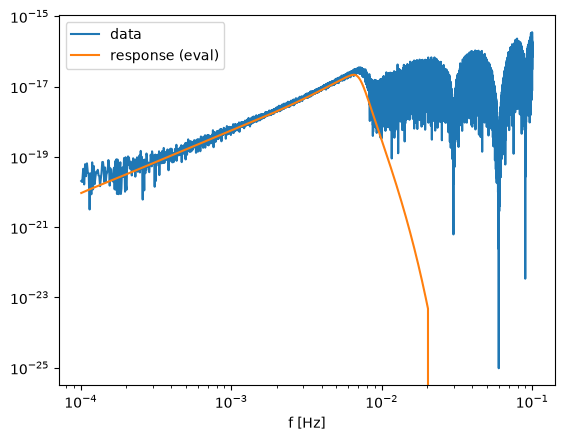

In [4]:
wf_ti.update_waveform(params_eval)
lisa_ti.update_detector_response(
    wf_ti.waveform_container,
    params_eval["ecliptic_longitude"],
    params_eval["ecliptic_latitude"],
    params_eval["polarization"],
    params_eval["coalescence_time"],
)

freqs = lisa_ti.tdi_data.data_info.frequency_samples_array
plt.figure()
plt.loglog(freqs, np.abs(lisa_ti.tdi_data.fd_data_numpy.A), label="data")
plt.loglog(freqs, np.abs(lisa_ti.tdi_response_numpy.A), label="response (eval)")
plt.xlabel("f [Hz]")
plt.legend()

In [5]:
# jax-backend
tdi_data_jax = TDIChannelData(backend="jax")
tdi_data_jax.set_fd_data_from_zero(
    channels,
    duration,
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
)
tdi_data_jax.set_fd_noise_power_density_from_model("LISA_SciRDv1", tdi_generation=tdi_gen)
noise_jax = tdi_data_jax.get_fd_noise_realization(seed=2026, output_type='numpy')
tdi_data_jax.add_into_fd_data(noise_jax)

lisa_jax = InterferometerAntenna(
    name="lisa_jax",
    tdi_data=tdi_data_jax,
    orbit_model=KaplerianHeliocentric(2.5e9, 0.0, -np.pi/9, backend="jax"),
    response_model=FDResponseModelMarset2018(backend="jax"),
    tdi_combination=FDMichelsonConstantEqualArm(
        generation=tdi_gen, orthogonal=True, backend="jax"
    ),
    backend="jax",
)
wf_jax = IMRPhenomXAS_jax(tdi_data_jax.frequency_samples, f_ref)
WaveformParams = namedtuple("WaveformParams", wf_jax.required_params)
wf_params_inj = WaveformParams(
    **{name: params_inj[name] for name in wf_jax.required_params}
)
lisa_jax.inject_signal(
    wf_jax.get_waveform(wf_params_inj),
    params_inj["ecliptic_longitude"],
    params_inj["ecliptic_latitude"],
    params_inj["polarization"],
    params_inj["coalescence_time"],

)


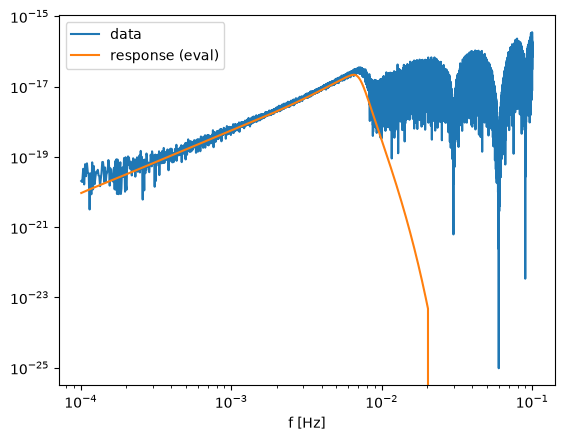

In [6]:
wf_params_eval = WaveformParams(
    **{name: params_eval[name] for name in wf_jax.required_params}
)
lisa_jax.update_detector_response(
    wf_jax.get_waveform(wf_params_eval),
    params_eval["ecliptic_longitude"],
    params_eval["ecliptic_latitude"],
    params_eval["polarization"],
    params_eval["coalescence_time"],
)

freqs = lisa_jax.tdi_data.data_info.frequency_samples_array
plt.figure()
plt.loglog(freqs, np.abs(lisa_jax.tdi_data.fd_data_numpy.A), label="data")
plt.loglog(freqs, np.abs(lisa_jax.tdi_response_numpy.A), label="response (eval)")
plt.xlabel("f [Hz]")
plt.legend()

In [7]:
data_np = lisa_ti.tdi_data.fd_data_numpy
resp_np = lisa_ti.tdi_response_numpy
psd_np = lisa_ti.tdi_data.fd_noise_power_density_numpy
df = lisa_ti.tdi_data.data_info.delta_frequency

data_stacked = jnp.asarray(
    np.stack([getattr(data_np, chan) for chan in channels], axis=-1)
)
resp_stacked = jnp.asarray(
    np.stack([getattr(resp_np, chan) for chan in channels], axis=-1)
)
psd_stacked = jnp.asarray(
    np.stack([getattr(psd_np, chan) for chan in channels], axis=-1)
)

ll_kernel_jax = noise_weighted_inner_product(data_stacked, resp_stacked, psd_stacked, df)
ll_kernel_ti = compute_whittle_likelihood_ti(
    channels,
    lisa_ti.tdi_data.fd_data,
    lisa_ti.tdi_response,
    lisa_ti.tdi_data.fd_noise_power_density,
    df,
)

print(f"jax (stacked (N_freq, N_channels)): {float(ll_kernel_jax):.15e}")
print(f"taichi kernel: {ll_kernel_ti:.15e}")
print(
    "relative difference: "
    f"{abs(float(ll_kernel_jax) - ll_kernel_ti) / abs(ll_kernel_ti):.3e}"
)
np.testing.assert_allclose(ll_kernel_jax, ll_kernel_ti, rtol=1e-12)

jax (stacked (N_freq, N_channels)): -2.359445241670086e+06
taichi kernel: -2.359445241670107e+06
relative difference: 9.079e-15


In [8]:
response_params = (
    "ecliptic_longitude",
    "ecliptic_latitude",
    "polarization",
    "coalescence_time",
)
Params = namedtuple("Params", (*wf_jax.required_params, *response_params))
peval = Params(**{name: params_eval[name] for name in Params._fields})

# for chans in [("A", "E", "T"), ("A", "E"), ("A",), ("E",), ("T",)]:
#     likelihood_ti = LikelihoodBilbyInterfaceTaichi(wf_ti, lisa_ti, chans)
#     ll_ti = likelihood_ti.log_likelihood(params_eval)

#     likelihood_jax = WhittleLikelihoodJax(wf_jax, lisa_jax, chans)
#     ll_jax = likelihood_jax.log_likelihood(peval)
#     ll_jax_jit = jax.jit(likelihood_jax.log_likelihood)(peval)

#     print(f"channels={chans}")
#     print(f"  taichi: {ll_ti:.10e}")
#     print(f"  jax (eager): {float(ll_jax):.10e}")
#     print(f"  jax (jit): {float(ll_jax_jit):.10e}")
#     print(
#         "  relative difference: "
#         f"{abs(float(ll_jax_jit) - ll_ti) / abs(ll_ti):.3e}"
#     )
#     np.testing.assert_allclose(ll_jax, ll_ti, rtol=1e-10)
#     np.testing.assert_allclose(ll_jax_jit, ll_ti, rtol=1e-10)

channels=('A', 'E', 'T')
  taichi: -2.3594452417e+06
  jax (eager): -2.3594452417e+06
  jax (jit): -2.3594452417e+06
  relative difference: 1.510e-12
channels=('A', 'E')
  taichi: -2.2937367567e+06
  jax (eager): -2.2937367567e+06
  jax (jit): -2.2937367567e+06
  relative difference: 1.553e-12
channels=('A',)
  taichi: -1.3158035953e+06
  jax (eager): -1.3158035953e+06
  jax (jit): -1.3158035953e+06
  relative difference: 1.498e-12
channels=('E',)
  taichi: -9.7793316140e+05
  jax (eager): -9.7793316140e+05
  jax (jit): -9.7793316140e+05
  relative difference: 1.578e-12
channels=('T',)
  taichi: -6.5708484941e+04
  jax (eager): -6.5708484941e+04
  jax (jit): -6.5708484941e+04
  relative difference: 7.087e-15


In [9]:
tdi_data_taiji_ti = TDIChannelData()
tdi_data_taiji_ti.set_fd_data_from_zero(
    channels, 
    duration, 
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
    )
tdi_data_taiji_ti.set_fd_noise_power_density_from_model("Taiji_TDC", tdi_generation=tdi_gen)
noise_taiji = tdi_data_taiji_ti.get_fd_noise_realization(seed=2026)
tdi_data_taiji_ti.add_into_fd_data(noise_taiji)
taiji_ti = InterferometerAntenna(
    name="taiji_ti",
    tdi_data=tdi_data_taiji_ti,
    orbit_model=KaplerianHeliocentric(3.0e9, 0.0, np.pi / 9),
    response_model=FDResponseModelMarset2018(),
    tdi_combination=FDMichelsonConstantEqualArm(generation=tdi_gen, orthogonal=True),
)

tdi_data_tianqin_ti = TDIChannelData()
tdi_data_tianqin_ti.set_fd_data_from_zero(
    channels, 
    duration, 
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
    )
tdi_data_tianqin_ti.set_fd_noise_power_density_from_model("Tianqin_GWSpace", tdi_generation=tdi_gen)
noise_tianqin = tdi_data_tianqin_ti.get_fd_noise_realization(seed=2026)
tdi_data_tianqin_ti.add_into_fd_data(noise_tianqin)
tianqin_ti = InterferometerAntenna(
    name="tianqin_ti",
    tdi_data=tdi_data_tianqin_ti,
    orbit_model=KeplerianGeocentric(1.0e8, 0.0, 0.0),
    response_model=FDResponseModelMarset2018(),
    tdi_combination=FDMichelsonConstantEqualArm(generation=tdi_gen, orthogonal=True),
)


In [10]:
tdi_data_taiji_jax = TDIChannelData(backend='jax')
tdi_data_taiji_jax.set_fd_data_from_zero(
    channels, 
    duration, 
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
    )
tdi_data_taiji_jax.set_fd_noise_power_density_from_model("Taiji_TDC", tdi_generation=tdi_gen)
noise_taiji = tdi_data_taiji_jax.get_fd_noise_realization(seed=2026, output_type='numpy')
tdi_data_taiji_jax.add_into_fd_data(noise_taiji)
taiji_jax = InterferometerAntenna(
    name="taiji_jax",
    tdi_data=tdi_data_taiji_jax,
    orbit_model=KaplerianHeliocentric(3.0e9, 0.0, np.pi / 9, backend='jax'),
    response_model=FDResponseModelMarset2018(backend='jax'),
    tdi_combination=FDMichelsonConstantEqualArm(generation=tdi_gen, orthogonal=True, backend='jax'),
    backend='jax',
)

tdi_data_tianqin_jax = TDIChannelData(backend='jax')
tdi_data_tianqin_jax.set_fd_data_from_zero(
    channels, 
    duration, 
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
    )
tdi_data_tianqin_jax.set_fd_noise_power_density_from_model("Tianqin_GWSpace", tdi_generation=tdi_gen)
noise_tianqin = tdi_data_tianqin_jax.get_fd_noise_realization(seed=2026, output_type='numpy')
tdi_data_tianqin_jax.add_into_fd_data(noise_tianqin)
tianqin_jax = InterferometerAntenna(
    name="tianqin_jax",
    tdi_data=tdi_data_tianqin_jax,
    orbit_model=KeplerianGeocentric(1.0e8, 0.0, 0.0, backend='jax'),
    response_model=FDResponseModelMarset2018(backend='jax'),
    tdi_combination=FDMichelsonConstantEqualArm(generation=tdi_gen, orthogonal=True, backend='jax'),
    backend='jax',
)


In [11]:
# dets_ti = (lisa_ti, taiji_ti, tianqin_ti)
# dets_jax = (lisa_jax, taiji_jax, tianqin_jax)

# for chans in [("A", "E", "T"), ("A", "E"), ("A",), ("E",), ("T",)]:
#     likelihood_ti = LikelihoodBilbyInterfaceTaichi(wf_ti, dets_ti, chans)
#     ll_ti = likelihood_ti.log_likelihood(params_eval)

#     likelihood_jax_bilby = LikelihoodBilbyInterfaceJax(wf_jax, dets_jax, chans)
#     ll_jax_bilby = likelihood_jax_bilby.log_likelihood(params_eval)

#     likelihood_jax = WhittleLikelihoodJax(wf_jax, dets_jax, chans)
#     ll_jax = likelihood_jax.log_likelihood(peval)
#     ll_jax_jit = jax.jit(likelihood_jax.log_likelihood)(peval)

#     print(f"channels={chans}")
#     print(f"  taichi: {ll_ti:.10e}")
#     print(f"  jax (bilby): {float(ll_jax_bilby):.10e}")
#     print(f"  jax (eager): {float(ll_jax):.10e}")
#     print(f"  jax (jit): {float(ll_jax_jit):.10e}")

#     print(
#         "  relative difference: "
#         f"{abs(float(ll_jax_bilby) - ll_ti) / abs(ll_ti):.3e}"
#     )
#     print(
#         "  relative difference: "
#         f"{abs(float(ll_jax_jit) - ll_ti) / abs(ll_ti):.3e}"
#     )
#     np.testing.assert_allclose(ll_jax, ll_ti, rtol=1e-10)
#     np.testing.assert_allclose(ll_jax_jit, ll_ti, rtol=1e-10)
#     np.testing.assert_allclose(ll_jax_bilby, ll_ti, rtol=1e-10)

channels=('A', 'E', 'T')
  taichi: -6.1408760535e+06
  jax (bilby): -6.1408760535e+06
  jax (eager): -6.1408760535e+06
  jax (jit): -6.1408760535e+06
  relative difference: 5.586e-13
  relative difference: 5.586e-13
channels=('A', 'E')
  taichi: -5.9437243212e+06
  jax (bilby): -5.9437243212e+06
  jax (eager): -5.9437243212e+06
  jax (jit): -5.9437243212e+06
  relative difference: 5.866e-13
  relative difference: 5.866e-13
channels=('A',)
  taichi: -3.1221347571e+06
  jax (bilby): -3.1221347571e+06
  jax (eager): -3.1221347571e+06
  jax (jit): -3.1221347571e+06
  relative difference: 6.249e-13
  relative difference: 6.249e-13
channels=('E',)
  taichi: -2.8215895642e+06
  jax (bilby): -2.8215895642e+06
  jax (eager): -2.8215895642e+06
  jax (jit): -2.8215895642e+06
  relative difference: 5.514e-13
  relative difference: 5.514e-13
channels=('T',)
  taichi: -1.9715173222e+05
  jax (bilby): -1.9715173222e+05
  jax (eager): -1.9715173222e+05
  jax (jit): -1.9715173222e+05
  relative differe

In [12]:
rng = np.random.default_rng(2026)

num = 1024
params_dict = {
        "chi_1": rng.uniform(-0.99, 0.99, num),
        "chi_2": rng.uniform(-0.99, 0.99, num),
        "ecliptic_longitude": rng.uniform(0.0, 2*np.pi, num),
        "ecliptic_latitude": rng.uniform(-np.pi/2, np.pi/2, num),
        "inclination": rng.uniform(0.0, np.pi, num),
        "polarization": rng.uniform(0.0, np.pi, num),
        "reference_phase": rng.uniform(-0.99, 0.99, num),
        "coalescence_time": np.zeros(num),
        "luminosity_distance": np.exp(rng.uniform(np.log(1e4), np.log(5e6), num)),
        "chirp_mass": rng.uniform(5e5, 2e6, num),
        "mass_ratio": rng.uniform(0.05, 0.99, num),
    }
params_dict = bilby.gw.conversion.generate_mass_parameters(params_dict)
display(list(params_dict.keys()))

samples_jax = Params(**{name: params_dict[name] for name in Params._fields})
sample_0 = Params(**{field: np.atleast_1d(getattr(samples_jax, field)[0]) for field in samples_jax._fields})
display(sample_0)
samples_df = pd.DataFrame(params_dict)
display(samples_df.iloc[0])


['chi_1',
 'chi_2',
 'ecliptic_longitude',
 'ecliptic_latitude',
 'inclination',
 'polarization',
 'reference_phase',
 'coalescence_time',
 'luminosity_distance',
 'chirp_mass',
 'mass_ratio',
 'total_mass',
 'mass_1',
 'mass_2',
 'symmetric_mass_ratio']

Params(chirp_mass=array([1373187.13017432]), symmetric_mass_ratio=array([0.2313749]), chi_1=array([-0.63570907]), chi_2=array([-0.50458447]), luminosity_distance=array([56265.33229683]), reference_phase=array([-0.18148062]), inclination=array([2.65262675]), ecliptic_longitude=array([5.42845254]), ecliptic_latitude=array([-0.88536357]), polarization=array([2.33777705]), coalescence_time=array([0.]))

chi_1                  -6.357091e-01
chi_2                  -5.045845e-01
ecliptic_longitude      5.428453e+00
ecliptic_latitude      -8.853636e-01
inclination             2.652627e+00
polarization            2.337777e+00
reference_phase        -1.814806e-01
coalescence_time        0.000000e+00
luminosity_distance     5.626533e+04
chirp_mass              1.373187e+06
mass_ratio              5.711565e-01
total_mass              3.304760e+06
mass_1                  2.103394e+06
mass_2                  1.201367e+06
symmetric_mass_ratio    2.313749e-01
Name: 0, dtype: float64

In [13]:
likelihood_ti = LikelihoodBilbyInterfaceTaichi(wf_ti, lisa_ti, ("A", "E", "T"))
likelihood_jax = WhittleLikelihoodJax(wf_jax, lisa_jax, ("A", "E", "T"))
likelihood_jax_bilby = LikelihoodBilbyInterfaceJax(wf_jax, lisa_jax, ("A", "E", "T"))

In [14]:
def map_fn(fn, batch_size=1):
    if batch_size > 0:
        mapped = lambda xs: jax.lax.map(fn, xs, batch_size=batch_size)
    else:
        mapped = jax.vmap(fn)
    return jax.jit(mapped)

In [17]:
ll_jax = map_fn(likelihood_jax.log_likelihood, 32)
print(ll_jax(sample_0))

print(likelihood_ti.log_likelihood(samples_df.iloc[0]))
print(likelihood_jax_bilby.log_likelihood(samples_df.iloc[0]))

[-2133785.71013164]
-2133785.7101317993
-2133785.710131639


In [18]:
start = time.perf_counter()
compiled_f = ll_jax.lower(samples_jax).compile()
end = time.perf_counter()
print(f"jit compile time: {end - start:.10f} sec.")


jit compile time: 13.8929931191 sec.


In [19]:
start = time.perf_counter()
res = compiled_f(samples_jax)
res.block_until_ready()
end = time.perf_counter()
print(f"jit execute time: {end - start:.10f} sec.")
print(np.asarray(res))

jit execute time: 0.5211113519 sec.
[ -2133785.71013159  -1113250.89853069  -1081407.79688099 ...
 -19091669.03520541  -1091380.89752811  -5878841.59988171]


In [20]:
# taichi: loop over all samples (timed)
t0 = time.perf_counter()
ll_ti_val = np.empty(num)
for i in range(num):
    ll_ti_val[i] = likelihood_ti.log_likelihood(samples_df.iloc[i].to_dict())
t_ti_total = time.perf_counter() - t0
print(f"ti time consuming: {t_ti_total}")

t0 = time.perf_counter()
ll_jax_bilby_val = np.empty(num)
for i in range(num):
    ll_jax_bilby_val[i] = likelihood_jax_bilby.log_likelihood(samples_df.iloc[i].to_dict())
t_jax_bilby_total = time.perf_counter() - t0
print(f"jax (bilby) time consuming: {t_jax_bilby_total}")

t0 = time.perf_counter()
ll_jax_val = np.asarray(ll_jax(samples_jax))
t_jax_total = (time.perf_counter() - t0)
print(f"jax time consuming: {t_jax_total}")


ti time consuming: 9.66449432587251
jax (bilby) time consuming: 1.1755525080952793
jax time consuming: 0.4961569469887763


In [23]:
print(f"samples: {num}")
print(f"  taichi: {t_ti_total:.3f} s total, {t_ti_total / num * 1e3:.3f} ms/sample")
print(f"  jax (vmap, compiled): {t_jax_total:.3f} s total, {t_jax_total / num * 1e3:.3f} ms/sample")
print(f"  jax (bilby): {t_jax_bilby_total:.3f} s total, {t_jax_bilby_total / num * 1e3:.3f} ms/sample")


samples: 1024
  taichi: 9.664 s total, 9.438 ms/sample
  jax (vmap, compiled): 0.496 s total, 0.485 ms/sample
  jax (bilby): 1.176 s total, 1.148 ms/sample


In [ ]:
""" old benchmark
samples: 4096
  taichi: 39.617 s total, 9.672 ms/sample
  jax (vmap, compiled): 156.435 s total, 38.192 ms/sample
"""

In [24]:
rel_diff = np.max(np.abs(ll_jax_val - ll_ti_val) / np.abs(ll_ti_val))
print(f"  max |relative difference| (jax vs taichi): {rel_diff:.3e}")
np.testing.assert_allclose(ll_jax_val, ll_ti_val, rtol=1e-10)
np.testing.assert_allclose(ll_jax_bilby_val, ll_ti_val, rtol=1e-10)

  max |relative difference| (jax vs taichi): 6.616e-12


In [25]:
# gradient of the jax log-likelihood w.r.t. all likelihood parameters,
# batched over samples with the same map_fn as the likelihood itself
grad_ll_jax = map_fn(jax.grad(likelihood_jax.log_likelihood), 32)

# sanity check on a single sample
g0 = grad_ll_jax(sample_0)
print("gradient at sample 0:")
for field in Params._fields:
    print(f"  dlogL/d{field:20s}: {np.asarray(getattr(g0, field))[0]:.6e}")

# compile once for the full sample set
start = time.perf_counter()
compiled_g = grad_ll_jax.lower(samples_jax).compile()
end = time.perf_counter()
print(f"grad jit compile time: {end - start:.10f} sec.")

# execute and time (per-sample gradient cost)
start = time.perf_counter()
grads = compiled_g(samples_jax)
jax.block_until_ready(grads)
end = time.perf_counter()
t_grad_total = end - start
print(f"grad jit execute time: {t_grad_total:.10f} sec.")
print(f"  gradient: {t_grad_total / num * 1e3:.3f} ms/sample")
print(f"  likelihood only: {t_jax_total / num * 1e3:.3f} ms/sample")

# report non-finite gradients (the waveform model produces NaN derivatives for
# some high-spin samples; see the diagnosis cell below)
print("non-finite gradient counts per field:")
for field in Params._fields:
    g = np.asarray(getattr(grads, field))
    n_bad = int((~np.isfinite(g)).sum())
    print(f"  dlogL/d{field:20s}: {n_bad}/{num}")

gradient at sample 0:
  dlogL/dchirp_mass          : 1.216666e+02
  dlogL/dsymmetric_mass_ratio: -1.174578e+08
  dlogL/dchi_1               : -1.175162e+07
  dlogL/dchi_2               : -5.846806e+06
  dlogL/dluminosity_distance : 3.681864e+01
  dlogL/dreference_phase     : -3.145785e+05
  dlogL/dinclination         : -1.051863e+06
  dlogL/decliptic_longitude  : -9.036353e+05
  dlogL/decliptic_latitude   : -1.700359e+06
  dlogL/dpolarization        : 3.327044e+05
  dlogL/dcoalescence_time    : 3.519117e+03
grad jit compile time: 137.3721687458 sec.
grad jit execute time: 1.8313103809 sec.
  gradient: 1.788 ms/sample
  likelihood only: 0.485 ms/sample
non-finite gradient counts per field:
  dlogL/dchirp_mass          : 7/1024
  dlogL/dsymmetric_mass_ratio: 7/1024
  dlogL/dchi_1               : 7/1024
  dlogL/dchi_2               : 7/1024
  dlogL/dluminosity_distance : 0/1024
  dlogL/dreference_phase     : 0/1024
  dlogL/dinclination         : 0/1024
  dlogL/decliptic_longitude  : 0/102